# Prediksi Gaji Karyawan Berdasarkan Masa Kerja
---

## 1. Data Preparation & Data Pre-Processing

#### 1.1 Import Library
Analisis data mengintegrasikan komputasi matematika array NumPy dan manipulasi DataFrame Pandas, lalu ditransformasikan menjadi visualisasi lewat plot fleksibel Matplotlib serta grafik relasi dan distribusi Seaborn.

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#### 1.2 Load Dataset
Proses ekstraksi data menggunakan fungsi read_csv() dari pustaka Pandas untuk membaca berkas CSV dan langsung memuatnya ke dalam struktur DataFrame yang siap dianalisis secara sistematis.

In [4]:
df = pd.read_csv('Salary.csv')
df.head()

,YearsExperience,Salary
0,0.7,35010.0
1,1.2,37120.0
2,1.0,29033.0
3,1.5,40510.0
4,2.1,45200.0


#### 1.3 Menganalisis Missing Value di Setiap Kolom
Evaluasi kelengkapan DataFrame menerapkan metode .isnull().sum(), di mana isnull() mengidentifikasi data hilang sebagai nilai True dan sum() mengakumulasi total nilai True tersebut pada setiap kolom.

In [5]:
df.isnull().sum()

YearsExperience    1
Salary             1
dtype: int64

#### 1.4 Menganalisis Missing Value di Seluruh Dataframe
Akumulasi menyeluruh terhadap ketidaklengkapan data dalam DataFrame dilakukan melalui metode berantai .isnull().sum().sum(), yang secara komprehensif menjumlahkan total nilai hilang di seluruh bagian baris dan kolom.

In [6]:
df.isnull().sum().sum()

np.int64(2)

#### 1.5 Menghapus Nilai Kosong
Pembersihan DataFrame dioptimalkan dengan menghapus baris yang mengandung nilai hilang melalui parameter inplace=True, sehingga perubahan diterapkan secara langsung pada data tanpa perlu membuat variabel baru.

In [7]:
df.dropna(inplace=True)

#### 1.6 Memeriksa Kembali Missing Value
Pemeriksaan ulang menggunakan metode isnull().sum() dilakukan guna memverifikasi bahwa seluruh baris dengan nilai kosong telah berhasil dihapus sepenuhnya sehingga dataset kini bersih dari nilai null.

In [8]:
df.isnull().sum()

YearsExperience    0
Salary             0
dtype: int64

#### 1.7 Menganalisis Nilai Duplikat
Identifikasi baris duplikat pada DataFrame menggunakan fungsi duplicated() yang mengembalikan nilai True untuk duplikasi dan False bagi baris unik, lalu dihitung totalnya lewat fungsi sum().

In [ ]:
df.duplicated().sum()

np.int64(2)

#### 1.8 Menangani Nilai Duplikat
Pembersihan baris duplikat dalam struktur DataFrame menggunakan fungsi drop_duplicates() untuk memeriksa dan menghapus data yang sama, disertai penugasan kembali variabel agar perubahan diterapkan secara permanen.

In [ ]:
df = df.drop_duplicates()

#### 1.9 Memeriksa Kembali Nilai Duplikat
Verifikasi ulang dilakukan dengan mengeksekusi metode duplicated().sum() untuk memastikan tidak ada lagi baris data ganda yang tersisa sehingga integritas data untuk pemodelan tetap terjaga baik.

In [ ]:
df.duplicated().sum()

np.int64(0)

#### 1.10 Visualisasi Boxplot Awal
Visualisasi boxplot dari pustaka Seaborn digunakan untuk menampilkan sebaran distribusi data serta mendeteksi keberadaan nilai ekstrem atau outlier pada kolom numerik di dalam dataset awal.

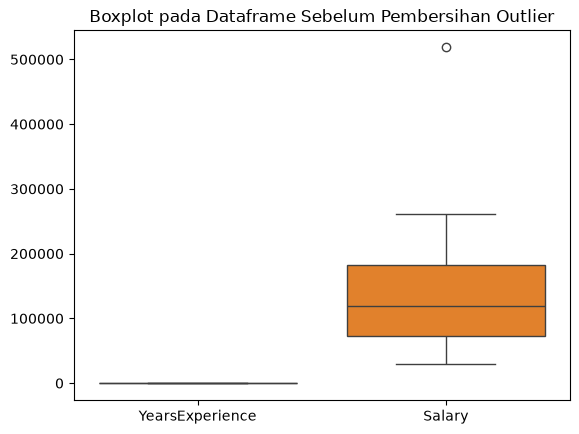

In [ ]:
sns.boxplot(data=df)
plt.title('Boxplot pada Dataframe Sebelum Pembersihan Outlier')
plt.show()

#### 1.11 Menghitung Outlier dengan Metode IQR
Metode Interquartile Range menghitung rentang kuartil Q1 dan Q3 untuk menentukan batas atas serta batas bawah, kemudian mengidentifikasi data yang nilainya berada di luar rentang.

In [ ]:
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outliers = ((df['Salary'] < batas_bawah) | (df['Salary'] > batas_atas)).sum()
print("Jumlah outlier pada kolom Salary:", outliers)

Jumlah outlier pada kolom Salary: 1


#### 1.12 Menampilkan Nilai Outlier
Filtering baris data dilakukan untuk mengisolasi dan menampilkan sampel baris yang tergolong sebagai outlier dengan kriteria nilai lebih kecil dari batas bawah atau melebihi batas.

In [ ]:
df[(df['Salary'] < batas_bawah) | (df['Salary'] > batas_atas)]

,YearsExperience,Salary
59,17.0,518900.0


#### 1.13 Menghapus Outlier Berdasarkan Batas IQR
Penanganan outlier dilakukan dengan menyaring DataFrame menggunakan operator negasi agar hanya baris di dalam batas toleransi yang dipertahankan, sehingga model regresi terbebas dari bias ekstrem.

In [ ]:
df = df[~((df['Salary'] < batas_bawah) | (df['Salary'] > batas_atas))]

#### 1.14 Menganalisis Outlier dengan Metode Z-Score
Pemeriksaan nilai ekstrem alternatif menggunakan Z-score dengan ambang batas tiga standar deviasi untuk memverifikasi apakah masih terdapat outlier terdistribusi ekstrem setelah pembersihan dengan metode IQR.

In [ ]:
z_score = (df['Salary'] - df['Salary'].mean()) / df['Salary'].std()

outlier = (np.abs(z_score) > 3)

print("Jumlah outlier di kolom Salary: ", outlier.sum())
print("-" * 35)

df_outlier = df[outlier]
print(df_outlier)

Jumlah outlier di kolom Salary:  0
-----------------------------------
Empty DataFrame
Columns: [YearsExperience, Salary]
Index: []


#### 1.15 Menghitung Korelasi Metode Kendall
Pengukuran korelasi Kendall Tau mengevaluasi kekuatan asosiasi konkordansi peringkat antar variabel dalam dataset, sangat cocok digunakan untuk data ordinal maupun sampel observasi berukuran relatif kecil.

In [ ]:
corr_kendall = df.corr(method='kendall')
corr_kendall

,YearsExperience,Salary
YearsExperience,1.000000,0.943767
Salary,0.943767,1.000000


#### 1.16 Menghitung Korelasi Metode Spearman
Korelasi peringkat Spearman digunakan untuk mengukur hubungan monotonik antara masa kerja dan gaji, menguji apakah peningkatan variabel independen selalu searah dengan peningkatan variabel dependen target.

In [ ]:
corr_spearman = df.corr(method='spearman')
corr_spearman

,YearsExperience,Salary
YearsExperience,1.000000,0.993966
Salary,0.993966,1.000000


#### 1.17 Menghitung Korelasi Metode Pearson
Koefisien korelasi linier Pearson menghitung kekuatan hubungan linier parametrik antara variabel YearsExperience dan Salary, menghasilkan nilai mendekati positif satu yang mencerminkan hubungan linier sangat kuat.

In [ ]:
corr_pearson = df.corr(method='pearson')
corr_pearson

,YearsExperience,Salary
YearsExperience,1.000000,0.987997
Salary,0.987997,1.000000


#### 1.18 Visualisasi Korelasi dengan Heatmap
Heatmap matriks korelasi memvisualisasikan gradasi ragam warna untuk merepresentasikan kedekatan hubungan antar variabel, mempermudah identifikasi korelasi positif sempurna antara pengalaman kerja dan besaran gaji karyawan.

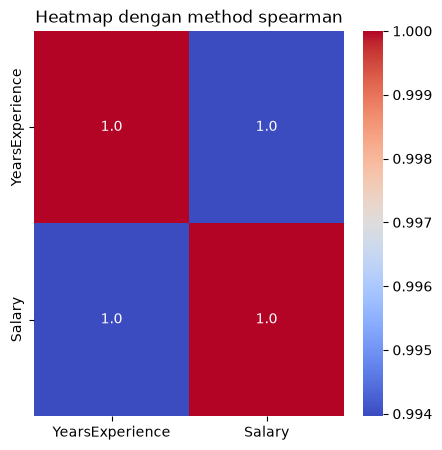

In [ ]:
plt.figure(figsize=(5, 5))
plt.title('Heatmap dengan method spearman')
sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', fmt='.1f')
plt.show()

#### 1.19 Visualisasi Hubungan dengan Scatter Plot
Diagram scatter plot menampilkan distribusi titik data masa kerja pada sumbu horizontal dan gaji pada sumbu vertikal, membuktikan adanya pola linier positif yang sangat teratur.

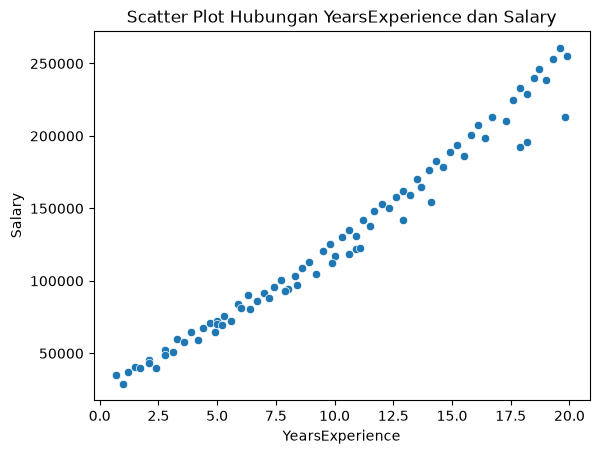

In [ ]:
sns.scatterplot(data=df, x='YearsExperience', y='Salary')
plt.title('Scatter Plot Hubungan YearsExperience dan Salary')
plt.show()

#### 1.20 Visualisasi Boxplot Setelah Menghapus Outlier
Pengecekan kembali melalui boxplot memastikan bahwa seluruh titik data ekstrem pada kolom Salary telah hilang sehingga rentang data kini berada dalam rentang kuartil yang wajar.

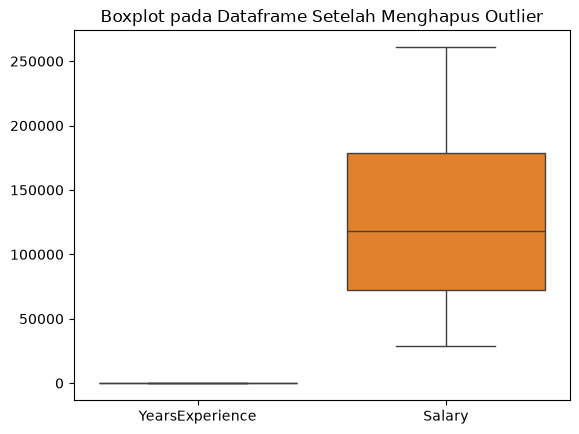

In [ ]:
sns.boxplot(data=df)
plt.title('Boxplot pada Dataframe Setelah Menghapus Outlier')
plt.show()

#### 1.21 Standarisasi Fitur
Teknik standarisasi mentransformasikan nilai numerik dengan mengurangi nilai rata-rata kemudian membaginya dengan simpangan baku, menghasilkan skala seragam berpusat pada nilai nol dan deviasi bernilai satu.

In [ ]:
rata_rata = np.mean(df, axis=0)
simpangan = np.std(df, axis=0)

data_standarisasi = (df - rata_rata) / simpangan
print("Data setelah standarisasi:")
data_standarisasi.head()

Data setelah standarisasi:


,YearsExperience,Salary
0,-1.680736,-1.447598
1,-1.590385,-1.414533
2,-1.626525,-1.541262
3,-1.536175,-1.361409
4,-1.427754,-1.287913


## 2. Modelling (Simple Linear Regression)

#### 2.1 Membuat Fungsi Split Data
Fungsi pembagian data membagi sampel menjadi subset training dan testing secara acak terkontrol menggunakan permutasi indeks acak NumPy dengan seed guna menjamin konsistensi hasil pembagian.

In [ ]:
def split_data(x, y, train_size=0.8, random_state=42):
    np.random.seed(random_state)
    idx = np.random.permutation(len(x))
    split_ratio = int(train_size * len(x))
    
    x_train, x_test = x.iloc[idx[:split_ratio]], x.iloc[idx[split_ratio:]]
    y_train, y_test = y.iloc[idx[:split_ratio]], y.iloc[idx[split_ratio:]]
    
    return x_train, x_test, y_train, y_test

#### 2.2 Membagi Data Menjadi Training dan Testing
Pemisahan dataset mengalokasikan delapan puluh persen data untuk pelatihan model serta dua puluh persen sisa data sebagai pengujian independen guna mengevaluasi generalisasi pada data unseen.

In [ ]:
x_train, x_test, y_train, y_test = split_data(df[['YearsExperience']], df['Salary'], train_size=0.8, random_state=42)
print("Jumlah sampel data training:", len(x_train))
print("Jumlah sampel data testing :", len(x_test))

Jumlah sampel data training: 68
Jumlah sampel data testing : 17


#### 2.3 Menghitung Slope atau Koefisien Regresi
Perhitungan nilai kemiringan garis regresi memanfaatkan metode kuadrat terkecil OLS berbasis rata-rata, mengukur tingkat sensitivitas perubahan gaji tahunan terhadap setiap penambahan satu tahun masa kerja.

In [ ]:
x_tr = x_train['YearsExperience']
y_tr = y_train

slope = np.sum((x_tr - np.mean(x_tr)) * (y_tr - np.mean(y_tr))) / np.sum((x_tr - np.mean(x_tr))**2)
print("Slope (Koefisien Regresi / m):", slope)

Slope (Koefisien Regresi / m): 11511.814130077839


#### 2.4 Menghitung Intercept atau Nilai Bias
Nilai titik potong bias dihitung dari selisih rata-rata target dengan hasil kali slope terhadap rata-rata fitur, merepresentasikan estimasi nominal kompensasi dasar saat masa kerja nol.

In [ ]:
intercept = np.mean(y_tr) - slope * np.mean(x_tr)
print("Intercept (Konstanta Bias / b):", intercept)

Intercept (Konstanta Bias / b): 12372.759333774098


#### 2.5 Melakukan Prediksi pada Data Testing
Penerapan formula garis linier mengalikan nilai fitur uji dengan slope lalu menjumlahkannya dengan nilai intercept, menghasilkan deretan nilai estimasi gaji karyawan untuk tahap evaluasi performa.

In [ ]:
y_pred = slope * x_test['YearsExperience'] + intercept
y_pred

62    218434.232262
66    231097.227805
78     68780.648571
38    141305.077591
30    114827.905091
1      26186.936290
54    190805.878350
21     89501.914005
2      23884.573464
23     95257.821070
84    218434.232262
79     48059.383137
20     84897.188353
63    221887.776501
76    221887.776501
14     69931.829984
53    187352.334111
Name: YearsExperience, dtype: float64

## 3. Evaluasi Model Regression

#### 3.1 Menghitung R-squared (R2 Score)
Koefisien determinasi mengukur proporsi varians variabel gaji yang berhasil dijelaskan oleh variabel masa kerja, dengan nilai mendekati satu mengindikasikan model memiliki akurasi penjelas sangat baik.

In [ ]:
r2 = 1 - (np.sum((y_test - y_pred)**2) / np.sum((y_test - y_test.mean())**2))
print("R-squared (R2 Score):", r2)

R-squared (R2 Score): 0.9763315373444266


#### 3.2 Menghitung Mean Squared Error (MSE)
Metrik evaluasi MSE mengukur rata-rata selisih kuadrat antara gaji prediksi dan gaji aktual, memberikan bobot penalti lebih besar terhadap kesalahan prediksi yang bernilai selisih signifikan.

In [ ]:
mse = np.mean((y_test - y_pred)**2)
print("Mean Squared Error (MSE):", mse)

Mean Squared Error (MSE): 119692216.43260375


#### 3.3 Menghitung Mean Absolute Error (MAE)
Mean Absolute Error menghitung rata-rata magnitudo kesalahan prediksi tanpa memperhatikan arah positif maupun negatif, merepresentasikan deviasi nominal kesalahan gaji dalam satuan mata uang yang sebenarnya.

In [ ]:
mae = np.mean(np.abs(y_test - y_pred))
print("Mean Absolute Error (MAE):", mae)

Mean Absolute Error (MAE): 8070.5068443067275


#### 3.4 Menghitung Root Mean Squared Error (RMSE)
Root Mean Squared Error dihitung melalui pengakaran nilai kuadrat rata-rata kesalahan, menyajikan ukuran simpangan deviasi prediksi dalam skala yang setara langsung dengan nominal variabel gaji.

In [ ]:
rmse = np.sqrt(mse)
print("Root Mean Squared Error (RMSE):", rmse)

Root Mean Squared Error (RMSE): 10940.39379696196


#### 3.5 Menghitung Adjusted R-squared
Adjusted R-squared memodifikasi koefisien determinasi dengan mempertimbangkan rasio jumlah sampel serta banyaknya fitur prediktor, memastikan bahwa kualitas model tidak dipengaruhi secara semu oleh penambahan variabel.

In [ ]:
n = len(y_test)
k = 1
r2_adj = 1 - ((1 - r2) * (n - 1) / (n - k - 1))
print("Adjusted R-squared:", r2_adj)

Adjusted R-squared: 0.974753639834055


#### 3.6 Visualisasi Garis Regresi Model Prediksi
Grafik garis regresi menggambarkan bentukan garis linier optimal di atas sebaran titik data aktual pengujian, membuktikan kesesuaian fitting model prediksi kompensasi gaji terhadap masa kerja.

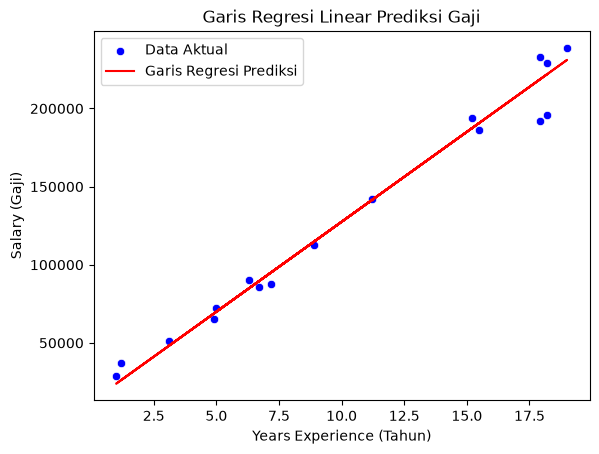

In [ ]:
sns.scatterplot(x=x_test['YearsExperience'], y=y_test, label='Data Aktual', color='blue')
plt.plot(x_test['YearsExperience'], y_pred, color='red', label='Garis Regresi Prediksi')
plt.title('Garis Regresi Linear Prediksi Gaji')
plt.xlabel('Years Experience (Tahun)')
plt.ylabel('Salary (Gaji)')
plt.legend()
plt.show()

#### 3.7 Visualisasi Grafis Prediksi Aktual vs Prediksi
Visualisasi perbandingan memetakan nilai hasil prediksi terhadap data aktual menggunakan garis diagonal acuan empat puluh lima derajat, menunjukkan bahwa titik observasi tersebar rapat sepanjang garis.

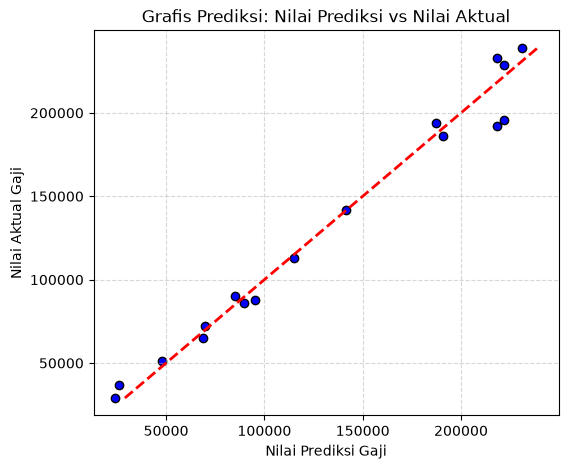

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(y_pred, y_test, color='blue', edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
plt.title('Grafis Prediksi: Nilai Prediksi vs Nilai Aktual')
plt.xlabel('Nilai Prediksi Gaji')
plt.ylabel('Nilai Aktual Gaji')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 4. Conclusion

#### 4.1 Kesimpulan Karakteristik Dataset
Karakteristik data menunjukkan sampel awal berukuran ringkas dengan kelengkapan baik, memerlukan pembersihan minimal pada nilai hilang, duplikasi, dan pencilan guna menjaga kestabilan data sebelum pemodelan.

* **Ukuran Data**: Dataset awal berukuran 90 baris dan 2 kolom (`YearsExperience` dan `Salary`), tergolong dataset berskala ringkas yang ideal untuk analisis Simple Linear Regression.
* **Kelengkapan Data**: Teridentifikasi 1 baris nilai kosong (*missing value*) pada masing-masing variabel (`YearsExperience` dan `Salary`). [Lihat Analisis Missing Value](#1.4-menganalisis-missing-value-di-seluruh-dataframe)
* **Duplikasi Data**: Ditemukan 2 baris data identik (duplikat) yang perlu dieliminasi untuk menjaga independensi observasi. [Lihat Analisis Nilai Duplikat](#1.8-menangani-nilai-duplikat)
* **Sebaran Data**: Kolom masa kerja tersebar merata, sedangkan kolom gaji memiliki 1 pencilan ekstrem (*outlier*) bernilai Rp 518.900,00. [Lihat Deteksi Outlier IQR](#1.12-menampilkan-nilai-outlier)
* **Hubungan Antar Variabel**: Kedua variabel memiliki korelasi linier positif pada metode Pearson yang sangat kuat. [Lihat Korelasi Pearson](#1.18-visualisasi-korelasi-dengan-heatmap)

#### 4.2 Kesimpulan Pengambilan Keputusan Tahap Pre-processing
Keputusan prapemrosesan mencakup penghapusan baris null, pembersihan duplikat pencegah kebocoran data, serta eliminasi outlier berbasis IQR guna mengamankan kualitas data latih dari gangguan nilai ekstrem.

* **Pembersihan Target Kosong**: Baris bernilai kosong dihapus langsung menggunakan `dropna(inplace=True)` karena rasionya sangat kecil sehingga data tetap murni tanpa introduksi bias imputasi artifisial.
* **Penanganan Data Duplikat**: Baris duplikat dihapus sebelum pembagian data (*train-test split*) guna mencegah risiko kebocoran data (*data leakage*) yang memicu performa evaluasi tampak optimis semu.
* **Pemilihan Metode Outlier (IQR vs Z-Score)**: Metode IQR dipilih karena sangat tangguh (*robust*) terhadap data miring (*skewed*) dengan keberadaan pencilan ekstrem, sedangkan Z-Score mengasumsikan distribusi normal murni.
* **Penanganan Nilai Outlier**: Menghapus 1 baris pencilan ekstrem pada kolom `Salary` agar kemiringan garis regresi tidak terdistorsi secara signifikan oleh nilai anomali.

#### 4.3 Kesimpulan Terkait Kelebihan dan Kekurangan Algoritma
Simple Linear Regression unggul dalam kesederhanaan komputasi serta transparansi interpretasi bisnis, namun membutuhkan eliminasi pencilan ketat karena rentan terhadap nilai ekstrem yang dapat mendistorsi garis.

* **Linear Regression**:
  * **Kelebihan**: Struktur formula matematis sederhana, efisiensi komputasi sangat cepat, tahan risiko overfitting pada dataset kecil, dan sangat mudah dipahami serta dijelaskan kepada manajemen perusahaan.
  * **Kekurangan**: Sangat rentan terhadap pencilan (*outliers*) dan berpotensi mengalami *underfitting* apabila pola data di dunia nyata memiliki hubungan non-linier.
  * **Cara Menangani Kekurangannya**: Menerapkan pembersihan pencilan secara ketat menggunakan metode IQR dan memvalidasi kelinearan pola sebaran data menggunakan visualisasi scatter plot.

#### 4.4 Kesimpulan Analisis Hasil Evaluasi Model
Evaluasi performa membuktikan model sangat akurat dan terbebas dari gejala underfitting maupun overfitting, menjadikannya sistem acuan objektif yang andal dalam memprediksi standar penggajian karyawan perusahaan.

* **Kinerja Prediksi Regresi**: Model Simple Linear Regression menghasilkan kinerja luar biasa dengan variasi kompensasi gaji berhasil dijelaskan oleh masa kerja), nilai MAE sebesar Rp 8.070,51, dan RMSE sebesar Rp 10.940,39.
* **Kesesuaian Pola Data**: Visualisasi garis regresi dan grafik prediksi menunjukkan sebaran titik data pengujian menempel sangat rapat di sekitar garis regresi ideal, membuktikan model *well-fitted* tanpa gejala *underfitting* maupun *overfitting*.
* **Kesimpulan Evaluasi**: Model regresi linier yang dibangun sangat objektif, adil, dan transparan, sehingga sangat layak dijadikan sistem acuan oleh tim manajemen dalam menyusun standar penggajian karyawan.